In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os

# ======================== 路径配置 ========================
# 设置基础路径
BASE_PATH = r'/home/ustc1958/lxy/1/MacroHFT/result/low_level/ETHUSDT/reward30000/slope/pos_2/4/label_2/seed_12345'

# 选择epoch和数据类型
EPOCH = 1  # 修改这里切换不同的epoch
DATA_TYPE = 'val'  # 'train' 或 'val'

# 构建数据目录
data_dir = os.path.join(BASE_PATH, f'epoch_{EPOCH}', DATA_TYPE)

# 文件后缀配置
# 训练数据(train)的val文件夹中的文件带有 _val 后缀
# 验证数据的文件名规则相同
FILE_SUFFIX = '_val' if DATA_TYPE == 'val' else ''

print(f"数据目录: {data_dir}")
print(f"文件后缀: '{FILE_SUFFIX}'")
print(f"目录是否存在: {os.path.exists(data_dir)}")


数据目录: /home/ustc1958/lxy/1/MacroHFT/result/low_level/ETHUSDT/reward30000/slope/pos_2/4/label_2/seed_12345/epoch_1/val
文件后缀: '_val'
目录是否存在: True


In [7]:
# ======================== 数据加载函数 ========================
# 统一的数据加载函数（兼容 dtype=object 的 npy 文件）

def load_scalar(path: str) -> float:
    """加载标量值的.npy文件"""
    arr = np.load(path, allow_pickle=True)
    try:
        return float(arr.item())
    except Exception:
        return float(np.asarray(arr).ravel()[0])

def load_array(path: str) -> np.ndarray:
    """加载数组类型的.npy文件（如reward, action等）"""
    arr = np.load(path, allow_pickle=True)
    if getattr(arr, 'dtype', None) == object:
        try:
            arr = np.concatenate(arr)
        except Exception:
            arr = np.array(list(arr), dtype=np.float64)
    return np.asarray(arr, dtype=np.float64).ravel()

def get_file_path(filename: str) -> str:
    """根据文件名和配置的后缀构建完整路径"""
    return os.path.join(data_dir, f'{filename}{FILE_SUFFIX}.npy')

def load_data_file(filename: str, is_scalar=True):
    """加载数据文件的通用函数"""
    path = get_file_path(filename)
    if not os.path.exists(path):
        raise FileNotFoundError(f"文件不存在: {path}")
    return load_scalar(path) if is_scalar else load_array(path)

print("数据加载函数已定义")

数据加载函数已定义


In [ ]:
# 计算当前目录去手续费后的收益率（%）
import os
import numpy as np
import json

def _try_path(base_dir, name, use_val):
    cands = []
    if use_val:
        cands.append(os.path.join(base_dir, f"{name}_val.npy"))
    cands.append(os.path.join(base_dir, f"{name}.npy"))
    for p in cands:
        if os.path.exists(p):
            return p
    return None

def _load_scalar_or_float(path):
    arr = np.load(path, allow_pickle=True)
    if hasattr(arr, "item"):
        try:
            return float(arr.item())
        except Exception:
            pass
    arr = np.array(arr).astype(float)
    return float(arr.reshape(-1)[0])

# 修改为实际的路径
base_dir = r'/home/ustc1958/lxy/1/MacroHFT/result/low_level/ETHUSDT/reward30000/slope/pos_2/4/label_2/seed_12345'
use_val = True

# 这里必须传入基础名（不要自带 _val）
req_path = _try_path(base_dir, "require_money", use_val)
rew_path = _try_path(base_dir, "reward", use_val)
fee_path = _try_path(base_dir, "commission_fee_history", use_val)

if req_path is None or rew_path is None:
    raise FileNotFoundError(f"缺少 require_money/reward 文件于: {base_dir}")

V1 = _load_scalar_or_float(req_path)
reward = np.load(rew_path, allow_pickle=True).astype(float).flatten()
pnl_net = float(np.sum(reward))
fee_sum = 0.0
if fee_path and os.path.exists(fee_path):
    fee_arr = np.load(fee_path, allow_pickle=True).astype(float).flatten()
    fee_sum = float(np.sum(fee_arr))

pnl_gross = pnl_net + fee_sum
tr_with_fee_pct = pnl_net / V1 * 100.0 if V1 != 0 else float("nan")
tr_no_fee_pct = pnl_gross / V1 * 100.0 if V1 != 0 else float("nan")

print(f"初始资金: {V1:.2f}")
print(f"去手续费后收益率: {tr_no_fee_pct:.2f}%")
print(f"含手续费收益率: {tr_with_fee_pct:.2f}%")
print(f"手续费合计: {fee_sum:.2f}")

FileNotFoundError: 缺少 require_money/reward 文件于: /home/ustc1958/lxy/1/MacroHFT/result/low_level/ETHUSDT/reward30000/slope/pos_2/4/label_2/seed_12345/epoch_1/val

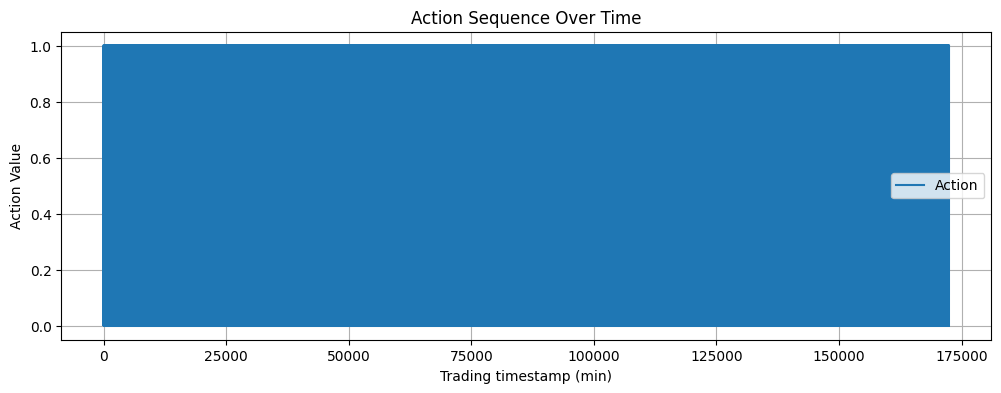

In [ ]:
# 可视化 action.npy 文件内容，分析策略行为
# ======================== 可视化 Action 序列 ========================

action_path = get_file_path('action')
if os.path.exists(action_path):
    action_arr = load_array(action_path)
    plt.figure(figsize=(12, 4))
    plt.plot(action_arr, label='Action', linewidth=1)
    plt.title(f'Action Sequence - Epoch {EPOCH} ({DATA_TYPE.upper()})')
    plt.xlabel('Trading timestamp (min)')
    plt.ylabel('Action Value')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print(f"未找到 action 文件: {action_path}")

In [4]:
import os
import numpy as np

# 复用已定义的 load_scalar / load_reward / _try_path / _load_scalar_or_float
# 注意：此单元仅用于验证 epoch_2 的回测结果，可按需改 base_dir
data_dir = base_dir  # 与上文保持一致
use_val_local = use_val

# 传入基础名（不要自带 _val）
req_path = _try_path(data_dir, "require_money", use_val_local)
rew_path = _try_path(data_dir, "reward", use_val_local)

if req_path is None or rew_path is None:
    raise FileNotFoundError(f"缺少 require_money/reward 文件于: {data_dir}")

V_1 = load_data_file('require_money', is_scalar=True)
reward = load_data_file('reward', is_scalar=False)

# 用 reward 和初始资金还原净值曲线
net_value = V_1 + np.cumsum(reward)
V_T = net_value[-1]  # 最终资金

# 返回率（百分比）
return_rate = (V_T / V_1 - 1) * 100 if V_1 != 0 else float('nan')

print(f'初始资金 V_1: {V_1:.2f}')
print(f'最终资金 V_T: {V_T:.2f}')
print(f'总回报率 TR: {return_rate:.4f}%')

FileNotFoundError: 缺少 require_money/reward 文件于: d:\Code\gitstorehouse\新建文件夹\MacroHFT\result\high_level\ETHUSDT\exp1_15epochs_3num\pos_3\seed_12345\epoch_1\val

In [5]:
# ======================== 计算六个金融指标（基于reward） ========================

reward = load_data_file('reward', is_scalar=False)
V_T = load_data_file('final_balance', is_scalar=True)
V_1 = load_data_file('require_money', is_scalar=True)
m = 525600  # 一年分钟数

# 1. 总回报率 TR
TR = (V_T - V_1) / V_1

# 2. 年度波动率 AVOL
AVOL = np.std(reward) * np.sqrt(m)

# 3. 最大回撤 MDD
cum_returns = np.cumsum(reward)
peak = np.maximum.accumulate(cum_returns)
drawdown = peak - cum_returns
MDD = np.max(drawdown)

# 4. 年化夏普比率 ASR
ASR = np.mean(reward) / np.std(reward) * np.sqrt(m) if np.std(reward) > 0 else 0

# 5. 年化卡玛比率 ACR
ACR = np.mean(drawdown) * m

# 6. 年度索提诺比率 ASoR
downside = reward[reward < 0]
DD = np.std(downside) if len(downside) > 0 else 0
ASoR = np.mean(downside) * np.sqrt(m) if DD > 0 else 0

print(f'Epoch {EPOCH} - {DATA_TYPE.upper()} 数据集金融指标:')
print(f'Total Return (TR): {TR:.4f}')
print(f'Annual Volatility (AVOL): {AVOL:.4f}')
print(f'Maximum Drawdown (MDD): {MDD:.4f}')
print(f'Annual Sharpe Ratio (ASR): {ASR:.4f}')
print(f'Annual Calmar Ratio (ACR): {ACR:.4f}')
print(f'Annual Sortino Ratio (ASoR): {ASoR:.4f}')

FileNotFoundError: 文件不存在: d:\Code\gitstorehouse\新建文件夹\MacroHFT\result\high_level\ETHUSDT\exp1_15epochs_3num\pos_3\seed_12345\epoch_1\val/reward_val.npy

In [ ]:
# ======================== 计算六个金融指标（百分比输出，基于净值曲线） ========================

V_1 = load_data_file('require_money', is_scalar=True)
reward = load_data_file('reward', is_scalar=False)
net_value = V_1 + np.cumsum(reward)
V_T = net_value[-1]
m = 525600  # 一年分钟数

# 1. 总回报率 TR
TR = (V_T - V_1) / V_1 * 100

# 2. 年度波动率 AVOL
r = np.diff(net_value) / net_value[:-1]  # 每步收益率
AVOL = np.std(r) * np.sqrt(m) * 100

# 3. 最大回撤 MDD
peak = np.maximum.accumulate(net_value)
drawdown = (peak - net_value) / peak
MDD = np.max(drawdown) * 100

# 4. 年化夏普比率 ASR
ASR = np.mean(r) / np.std(r) * np.sqrt(m) if np.std(r) > 0 else 0

# 5. 年化卡玛比率 ACR
ACR = (np.mean(r) * m) / (MDD/100) if MDD > 0 else np.nan

# 6. 年度索提诺比率 ASoR
downside = r[r < 0]
DD = np.std(downside) if len(downside) > 0 else 0
ASoR = np.mean(r) / DD * np.sqrt(m) if DD > 0 else np.nan

print(f'Epoch {EPOCH} - {DATA_TYPE.upper()} 数据集金融指标（百分比）:')
print(f'Total Return (TR): {TR:.2f}%')
print(f'Annual Volatility (AVOL): {AVOL:.2f}%')
print(f'Maximum Drawdown (MDD): {MDD:.2f}%')
print(f'Annual Sharpe Ratio (ASR): {ASR:.2f}')
print(f'Annual Calmar Ratio (ACR): {ACR:.2f}')
print(f'Annual Sortino Ratio (ASoR): {ASoR:.2f}')

Total Return (TR): 1.75%
Annual Volatility (AVOL): 10.72%
Maximum Drawdown (MDD): 4.63%
Annual Sharpe Ratio (ASR): 0.44
Annual Calmar Ratio (ACR): 1.02
Annual Sortino Ratio (ASoR): 0.19


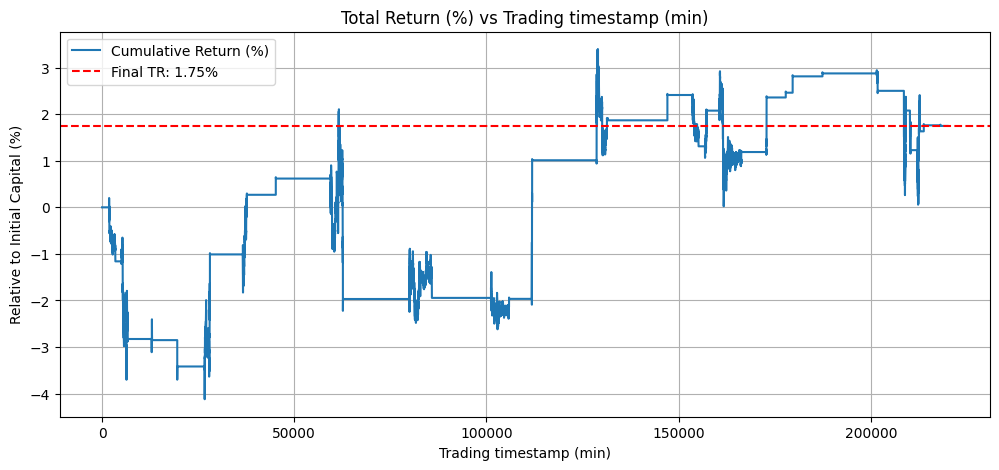

In [ ]:
# ======================== 可视化累计收益率曲线 ========================
V_1 = load_data_file('require_money', is_scalar=True)
reward = load_data_file('reward', is_scalar=False)
cum_return = (np.cumsum(reward)) / V_1 * 100  # 累计收益率百分比
final_tr = cum_return[-1]
timestamps = range(len(cum_return))

plt.figure(figsize=(12, 5))
plt.plot(timestamps, cum_return, label='Cumulative Return (%)', linewidth=1.5)
plt.axhline(final_tr, color='r', linestyle='--', linewidth=1, label=f'Final TR: {final_tr:.2f}%')
plt.axhline(0, color='gray', linestyle='-', linewidth=0.5, alpha=0.5)
plt.title(f'Total Return (%) - Epoch {EPOCH} ({DATA_TYPE.upper()})')
plt.xlabel('Trading timestamp (min)')
plt.ylabel('Relative to Initial Capital (%)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# 用 reward 和初始资金还原净值曲线，并计算六个金融指标（百分比输出）
V_1 = load_scalar(os.path.join(data_dir, 'require_money_val.npy'))
reward = load_reward(os.path.join(data_dir, 'reward_val.npy'))
net_value = V_1 + np.cumsum(reward)
V_T = net_value[-1]
m = 525600  # 一年分钟数

# 1. 总回报率 TR
TR = (V_T - V_1) / V_1 * 100

# 2. 年度波动率 AVOL
r = np.diff(net_value) / net_value[:-1]  # 每步收益率
AVOL = np.std(r) * np.sqrt(m) * 100

# 3. 最大回撤 MDD
peak = np.maximum.accumulate(net_value)
drawdown = (peak - net_value) / peak
MDD = np.max(drawdown) * 100

# 4. 年化夏普比率 ASR
ASR = np.mean(r) / np.std(r) * np.sqrt(m)

# 5. 年化卡玛比率 ACR
ACR = (np.mean(r) * m) / (MDD/100) if MDD > 0 else np.nan

# 6. 年度索提诺比率 ASoR
downside = r[r < 0]
DD = np.std(downside) if len(downside) > 0 else 0
ASoR = np.mean(r) / DD * np.sqrt(m) if DD > 0 else np.nan

print(f'Total Return (TR): {TR:.2f}%')
print(f'Annual Volatility (AVOL): {AVOL:.2f}%')
print(f'Maximum Drawdown (MDD): {MDD:.2f}%')
print(f'Annual Sharpe Ratio (ASR): {ASR:.2f}')
print(f'Annual Calmar Ratio (ACR): {ACR:.2f}')
print(f'Annual Sortino Ratio (ASoR): {ASoR:.2f}')

## 分析其他 Epoch

如需分析其他epoch，请修改第一个单元格中的配置：
- `EPOCH = 2`  # 修改epoch编号
- `DATA_TYPE = 'val'`  # 或 'train'

然后重新运行下面的单元格即可。

Total Return (TR): -92.88%
Annual Volatility (AVOL): 7.45%
Maximum Drawdown (MDD): 92.88%
Annual Sharpe Ratio (ASR): -108.09
Annual Calmar Ratio (ACR): -8.67
Annual Sortino Ratio (ASoR): -107.23


Initial Capital: 5265.16
Final TR: -92.88%


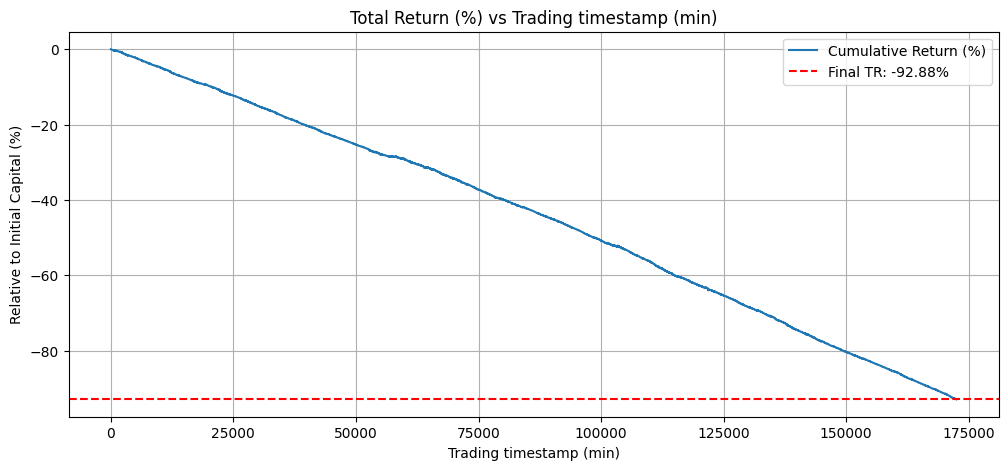

In [28]:
# 可视化累计收益率（资金曲线）并标注最终TR值，y轴改为“Relative to Initial Capital (%)”
V_1 = load_scalar(os.path.join(data_dir, 'require_money_val.npy'))
print(f'Initial Capital: {V_1:.2f}')
reward = load_reward(os.path.join(data_dir, 'reward_val.npy'))
cum_return = (np.cumsum(reward)) / V_1 * 100  # 累计收益率百分比
final_tr = cum_return[-1]
print(f'Final TR: {final_tr:.2f}%')
timestamps = range(len(cum_return))
plt.figure(figsize=(12, 5))
plt.plot(timestamps, cum_return, label='Cumulative Return (%)')
plt.axhline(final_tr, color='r', linestyle='--', label=f'Final TR: {final_tr:.2f}%')
plt.title('Total Return (%) vs Trading timestamp (min)')
plt.xlabel('Trading timestamp (min)')
plt.ylabel('Relative to Initial Capital (%)')
plt.legend()
plt.grid(True)
plt.show()